# Drift Diffusion Model (DDM) analysis for SJ task
**List of contents:**\
1- DDM Model based on Prior Response\
2- DDM Model based on Prior Stimulus\
3- DDM for general data

This script fits a DDM model using PyDDM for each participant,SOA condition, and prior response condition.\
The goal is to estimate the following parameters:
- drift rate (v)
- noise (σ)
- starting point (z)
- non-decision time (t0)

Model fit is evaluated by comparing predicted vs observed:
- RT quantiles (20%, 50%, 80%)
- accuracy

In [1]:
import pyddm
from pyddm import Sample
import pyddm.plot
import matplotlib.pyplot as plt
import pandas as pd
from pyddm.models import LossRobustLikelihood, LossLikelihood
import os
import numpy as np
from scipy.stats import pearsonr, spearmanr

###############################################################\
###############################################################
# 1- DDM Model based on Prior Response
**List of contents:**\
1-1 Fitting DDM\
1-2 Investigating fits and exclusions\
1-3 Cross-Validation

In [2]:
df = pd.read_excel("files/SJ_prior_response_data.xlsx")

In [3]:
df['resp_num'] = df['resp'].map({'synchrony': 1, 'asynchrony': 0})

In [5]:
df

,participant,pre_resp,SOA,resp,rt,resp_num
0,1,asynchrony,-400,asynchrony,1.437342,0
1,1,asynchrony,-400,asynchrony,1.169998,0
2,1,asynchrony,-400,asynchrony,1.236840,0
3,1,asynchrony,-400,asynchrony,1.186734,0
4,1,asynchrony,-400,asynchrony,1.403907,0
...,...,...,...,...,...,...
11200,22,synchrony,400,asynchrony,0.785775,0
11201,22,synchrony,400,asynchrony,0.852618,0
11202,22,synchrony,400,asynchrony,0.786604,0
11203,22,synchrony,400,asynchrony,0.719479,0


###############################################################
## 1-1 Fitting DDM

In [6]:
# DataFrame to store the final results
params = pd.DataFrame()

# List of participants
participants = df['participant'].unique()

# List of previous responses (pre_resp)
pre_resps = df['pre_resp'].unique()

# List of SOAs available in the participant's data
SOAs = df['SOA'].unique()

# Loop over each participant
for participant in participants:
    print(participant)
    # Filter data for the specific participant
    d = df[df['participant'] == participant]

    # Loop over each pre_resp
    for pre_resp in pre_resps:
        # Filter data based on pre_resp
        d_pre_resp = d[d['pre_resp'] == pre_resp]

        # Loop over each SOA
        for soa in SOAs:
            # Filter data for the specific SOA
            d_soa = d_pre_resp[d_pre_resp['SOA'] == soa]

            # Fit the DDM model with variable noise and fixed boundary = 1
            model = pyddm.gddm(drift="d",
                               noise="noise",  # noise as a free parameter
                               bound=1.0,      # fix boundary at 1
                               nondecision='t0', 
                               starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},  # parameters to be fitted
                               T_dur=d_soa['rt'].max() + 0.01)

            # Prepare data for the model
            data = Sample.from_pandas_dataframe(d_soa, rt_column_name="rt", choice_column_name="resp_num")

            # Fit the model to the data
            model.fit(
                sample=data, 
                lossfunction=LossRobustLikelihood, 
                verbose=False
            )

            # Extract fitted parameters
            p = model.parameters()

            # Create a DataFrame to store results for this combination of pre_resp, SOA, and participant
            pp = pd.DataFrame({
                'participant': [participant],
                'pre_resp': [pre_resp],  # add pre_resp to the results
                'SOA': [soa],
                'drift': [p['drift']['drift']],
                'noise': [p['noise']['noise']],  # store noise as a fitted parameter
                'bound': [1.0],  # fixed boundary value
                'Z': [p['IC']['x0']],
                't0': [p['overlay']['nondectime']]
            })

            # Append results to the final DataFrame
            params = pd.concat([params, pp], ignore_index=True)

1


Info: Params [-1.40668956e+00  2.65748129e-01  7.04486023e-01  1.41373299e-04] gave -1.8920572174352634
Info: Params [-0.886699    0.19569155  0.06752423  0.00167652] gave -0.15110191655756539
Info: Params [-3.99624866  1.82119726  0.36770674  0.93756135] gave -1.261354873956118
Info: Params [0.77269299 1.9291516  0.40028502 0.86798301] gave -1.0437484168845885
Info: Params [2.09565327 1.07341487 0.41442986 0.77012752] gave -2.579233785868066
Info: Params [1.22622462 1.23920455 0.1398866  0.53880314] gave 3.9685436716251
Info: Params [ 1.6107104   0.3504386  -0.54522165  0.00375007] gave -1.7150007293157787
Info: Params [2.61481689 1.72508761 0.10711855 0.75791138] gave -1.1005033548867804
Info: Params [ 1.52054377  0.30448825 -0.61108976  0.00159267] gave -1.183493731576495
Info: Params [ 1.25730489  0.20702012 -0.21152701  0.00196345] gave -4.0593542243141485
Info: Params [1.84573224 0.57695914 0.09497217 0.37597218] gave -2.5557522492568348
Info: Params [2.26613201 0.76966418 0.1872

3


Info: Params [-1.72007133  0.5139512   0.05045319  0.54093167] gave -2.3545688583748103
Info: Params [-0.61200068  0.77166567 -0.02647157  0.47106957] gave 24.04725517188528
Info: Params [-0.96412974  0.70635666  0.69303035  0.94990034] gave 22.54478333334937
Info: Params [-0.29327858  0.96213645  0.48380476  0.76915858] gave 17.071675482606302
Info: Params [-0.14154885  0.7540708   0.46177336  0.62430606] gave 33.75070746690865
Info: Params [0.33359822 0.85065624 0.28824526 0.58327463] gave 22.756156154980893
Info: Params [-0.2589234   0.68581666  0.74949682  0.78975532] gave 20.68628314247622
Info: Params [-0.17728949  0.7691447   0.49391663  0.60212811] gave 35.55991476405276
Info: Params [-0.44490124  0.5765322   0.6747008   0.5650481 ] gave 37.36883315375586
Info: Params [-0.14471493  0.86860622  0.47389795  0.81327049] gave 28.032043546732105
Info: Params [-0.39605203  0.69289608  0.60651534  0.49876132] gave 36.33542351315521
Info: Params [-0.32447225  0.78671605  0.56752068  0.

4


Info: Params [-1.90822713  1.43305218 -0.06705544  0.8831274 ] gave 2.806449885801176
Info: Params [ 0.15903823  1.16288667 -0.28605968  0.67252619] gave 19.794544390806763
Info: Params [ 0.58878723  1.18098475 -0.37422733  0.65203216] gave 16.838768792898133
Info: Params [ 1.60087319  1.58782274 -0.49380347  0.68974515] gave 4.10707610917
Info: Params [ 0.716296    1.00355215 -0.37189527  0.5206251 ] gave 27.297515580438308
Info: Params [ 1.14194909  1.55210483 -0.36754797  0.83336155] gave 13.162368479404346
Info: Params [ 0.44726224  1.42394441 -0.15958396  0.6970646 ] gave 12.338367251565874
Info: Params [ 0.37240082  1.03532492 -0.26299885  0.58139192] gave 21.74622849617557
Info: Params [-0.34834012  1.71998985  0.17158795  0.73812492] gave 7.483471300603202
Info: Params [ 0.9558407   1.19886939 -0.56045871  0.6266663 ] gave 14.170091783962334
Info: Params [ 0.47033762  1.160765   -0.30377277  0.65959863] gave 15.046386022075149
Info: Params [-0.86410558  1.1784512   0.33284648  

... (94 outputs left out)

Info: Params [0.82753411 1.15970347 0.79712081 0.9497877 ] gave -0.8088822098770942
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'synchrony'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'asynchrony'] = 0
Info: Params [-1.77064343  1.4800881  -0.19517643  0.92390045] gave 1.292597019049294
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy 

Info: Params [ 2.01374506  0.62650112 -0.11005744  0.37580215] gave -3.4853052523649404
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'synchrony'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'asynchrony'] = 0
Info: Params [1.01287388 0.47579678 0.39784948 0.39670279] gave 4.609686689620869
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy 

Info: Params [0.29878875 0.92041632 0.13410279 0.56539037] gave 28.242682003460374
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'synchrony'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'asynchrony'] = 0
Info: Params [ 2.64804763  0.71192388 -0.07099688  0.50941605] gave -8.968374313524944
C:\Users\sajjad\AppData\Local\Temp\ipykernel_18728\868739866.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy 

     participant    pre_resp  SOA     drift     noise  bound         Z  \
0              1  asynchrony   40  1.344959  0.973749    1.0  0.637828   
1              1  asynchrony   80  0.920854  1.426294    1.0  0.192980   
2              1  asynchrony -250 -4.017900  1.819702    1.0  0.370737   
3              1  asynchrony    0  2.388355  0.834460    1.0  0.168723   
4              1  asynchrony  -60  1.379317  0.276212    1.0 -0.460243   
..           ...         ...  ...       ...       ...    ...       ...   
961           21   synchrony  400 -1.855303  0.809294    1.0 -0.284088   
962           21   synchrony    0  1.825831  0.402243    1.0 -0.274119   
963           21   synchrony  100  1.839889  0.988074    1.0 -0.139623   
964           21   synchrony   80  1.119853  0.662126    1.0  0.422598   
965           21   synchrony -150  1.250983  0.560289    1.0  0.406411   

           t0  
0    0.656980  
1    0.621318  
2    0.938288  
3    0.519444  
4    0.003616  
..        ...  

In [7]:
params.to_excel("files/SJ_prior_response_DDM_parameters.xlsx", index=False)

###############################################################
## 1-2 Investigating fits and exclusions

In [5]:
# calculate predicted and observed statistics
data_list = []
model_list = []

# Group empirically observed dataset by experimental factors
groups = df.groupby(['participant', 'SOA', 'pre_resp'])

for (participant, soa, pre_resp), d in groups:
    # 1. Calculate empirical RT quantiles and visual-first choice probability
    p_obs = {
        'participant': participant,
        'SOA': soa,
        'pre_resp': pre_resp,
        'q1': d['rt'].quantile(.2),
        'q2': d['rt'].quantile(.5),
        'q3': d['rt'].quantile(.8),
        'p_vis': d['resp_num'].mean()
    }
    data_list.append(p_obs)

    # 2. Extract corresponding fitted parameters safely
    p = params[(params['participant'] == participant) & 
               (params['SOA'] == soa) & 
               (params['pre_resp'] == pre_resp)].reset_index(drop=True)


    # Map parameter column names dynamically (handles uppercase/lowercase variations)
    drift_val = float(p['drift'][0])
    noise_val = float(p['noise'][0])
    t0_val = float(p['t0'][0])
    z_val = float(p['Z'][0])

    # 3. Solve PyDDM Model

    model = pyddm.gddm(
        drift=drift_val,
        noise=noise_val,
        bound=1.0,
        nondecision=t0_val, 
        starting_position=min(max(z_val,-.98),.98),
        T_dur=10, dt=.0001, dx=.0001
    )
    s = model.solve()

    # 4. Store predictions
    p_pred = {
        'participant': participant,
        'SOA': soa,
        'pre_resp': pre_resp,
        'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
        'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
        'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
        'p_vis': s.prob('correct')
    }
    model_list.append(p_pred)
        


# Convert lists to DataFrames
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)


In [17]:
# investigate the exclutions
val = 'q1'
r1 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
print(sum(~r1))
val = 'q2'
r2 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r1,r2)
print(sum(~r2))
val = 'q3'
r3 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r,r3)
print(sum(~r3))
val = 'p_vis'
r4 = (model_[val] >= data_[val]-.1) & (model_[val] <= data_[val]+.1)
r = np.logical_and(r,r4)
print(sum(~r4))

1
3
5
5


In [18]:
sum(~r)

14

In [27]:
data_[~r]

,participant,SOA,pre_resp,q1,q2,q3,p_vis
55,3,-150,synchrony,1.480877,2.774377,3.121489,0.555556
58,3,-100,asynchrony,0.906424,2.255997,2.911049,0.714286
164,5,40,asynchrony,0.602060,0.735648,1.504221,1.000000
360,10,200,asynchrony,0.869942,1.203867,1.558101,0.500000
378,11,-120,asynchrony,0.545655,0.635410,0.665471,0.857143
421,12,-200,synchrony,0.695770,0.885814,1.049673,0.800000
449,12,120,synchrony,1.073221,1.286959,2.182552,0.333333
458,12,400,asynchrony,1.103278,1.244955,1.470994,0.083333
484,13,20,asynchrony,0.802406,0.902678,1.734792,1.000000
500,13,250,asynchrony,0.752591,1.654603,2.189266,0.166667


In [11]:
params[r].reset_index(drop=True).to_excel("files/SJ_prior_response_DDM_parameters_clean.xlsx", index=False)

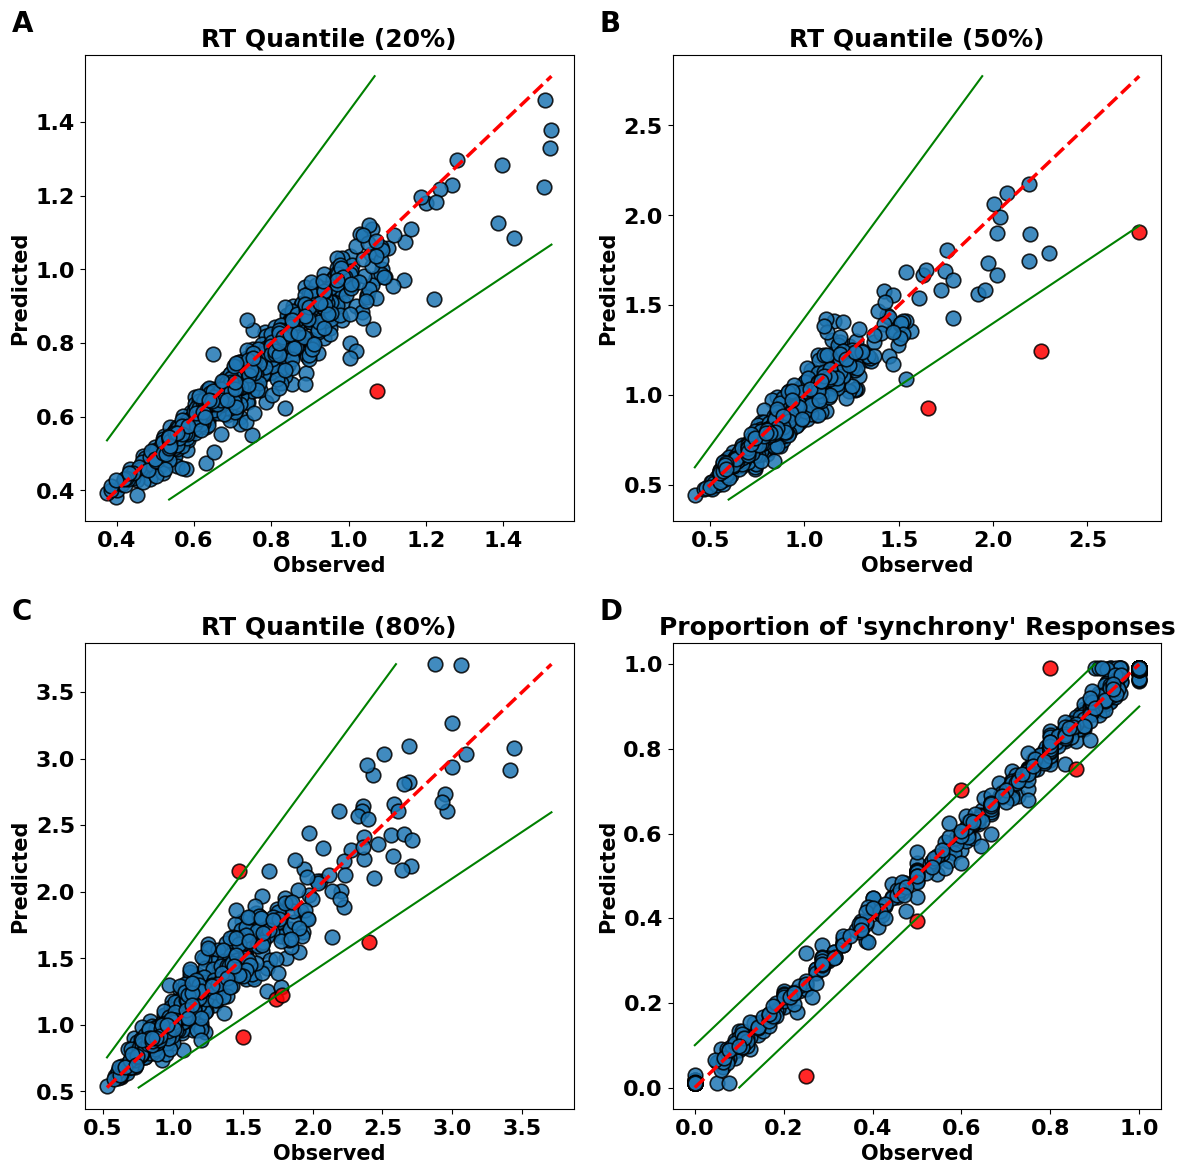

In [26]:
# Configure publication-ready figure formatting parameters
plt.rcParams.update({
    "font.size": 16,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Define diagnostic dimensions (Panel D title updated to reflect accurate psychophysical measure)
plots = [
    (data_['q1'], model_['q1'], "RT Quantile (20%)"),
    (data_['q2'], model_['q2'], "RT Quantile (50%)"),
    (data_['q3'], model_['q3'], "RT Quantile (80%)"),
    (data_['p_vis'], model_['p_vis'], "Proportion of 'synchrony' Responses")
]

panel_labels = ["A", "B", "C", "D"]
R = [r1,r2,r3,r4]
# Iterate over grid cells and plot empirical vs. predicted measures
for i, ax, (x, y, title), label in zip(np.arange(4), axes.flatten(), plots, panel_labels):

    # Render individual participant-SOA data points
    ax.scatter(x[r], y[r],
               s=110,
               edgecolor="black",
               linewidth=1.2,
               alpha=0.85)
    ax.scatter(x[~R[i]], y[~R[i]],
               s=110,
               edgecolor="black",
               c='red',
               linewidth=1.2,
               alpha=0.85)

    # Plot the diagonal line of identity (y = x) representing perfect generative fit
    min_val = min(min(x.dropna()), min(y.dropna()))
    max_val = max(max(x.dropna()), max(y.dropna()))
    ax.plot([min_val, max_val], [min_val, max_val],
            color="red",
            linestyle='--',
            linewidth=2.5)
    if title=="Proportion of 'synchrony' Responses":
        ax.plot([.1, 1], [0, .9],
                color="green",
                linewidth=1.5)
        ax.plot([0, .9], [.1, 1],
                color="green",
                linewidth=1.5)
    else:
        ax.plot([1/.7*min_val, max_val], [min_val, .7*max_val],
                color="green",
                linewidth=1.5)
        ax.plot([min_val, .7*max_val], [1/.7*min_val, max_val],
                color="green",
                linewidth=1.5)

    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_xlabel("Observed", fontsize=15)
    ax.set_ylabel("Predicted", fontsize=15)

    # Add panel identification labels (A-D)
    ax.text(-0.15, 1.05, label,
            transform=ax.transAxes,
            fontsize=20,
            fontweight="bold")

plt.tight_layout()

# Save vector PDF for manuscript integration and OSF repository
plt.savefig("figures/SJ_prior_response_DDMfits.pdf",
            format="pdf",
            bbox_inches="tight")

plt.show()
plt.close()

###############################################################
## 1-3 Cross-Validation

Objective: \
This script executes an out-of-sample predictive cross-validation analysis to evaluate model ability to detect individual differences and generalizability and rule out potential overfitting in the TOJ paradigm. For each unique cell (Participant × Prior Response × SOA), trials are split into independent training (odd-indexed) and testing (even-indexed) subsets. The boundaries represent orthogonal temporal alternatives: Upper (1) for 'visual-first' (v) and Lower (0) for 'auditory-first' (a).Parameters are optimized via MLE on the training subset, and the predictive RT and choice statistics are validated against the held-out empirical testing set.

In [11]:
# split-half the data
current_df = df
current_df['trial_index'] = current_df.groupby(['participant', 'pre_resp', 'SOA']).cumcount()
df_odd = current_df[current_df['trial_index'] % 2 != 0].copy()   # Training Set (Odd trials)
df_even = current_df[current_df['trial_index'] % 2 == 0].copy()  # Testing Set (Even trials)

In [15]:
# fit the model on odd trials and calculate predictive and observed statistics
data_list = []
model_list = []

participants = current_df['participant'].unique()
pre_resps = current_df['pre_resp'].unique()
SOAs = current_df['SOA'].unique()

# Nested loops to isolate each model fitting cell independently
for participant in participants:
    d_odd_p = df_odd[df_odd['participant'] == participant]
    d_even_p = df_even[df_even['participant'] == participant]
    
    for pre_resp in pre_resps:
        d_odd_pr = d_odd_p[d_odd_p['pre_resp'] == pre_resp]
        d_even_pr = d_even_p[d_even_p['pre_resp'] == pre_resp]
        
        for soa in SOAs:
            d_soa_train = d_odd_pr[d_odd_pr['SOA'] == soa].copy()
            d_soa_test = d_even_pr[d_even_pr['SOA'] == soa].copy()

            model = pyddm.gddm(drift="d", noise="noise", bound=1.0, nondecision='t0', starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},
                               T_dur=d_soa_train['rt'].max() + 0.01)
            
            train_sample = Sample.from_pandas_dataframe(d_soa_train, rt_column_name="rt", choice_column_name="resp_num")
            model.fit(sample=train_sample, verbose=False, lossfunction=LossRobustLikelihood)
            
            
            p_obs = {
                'participant': participant,
                'SOA': soa,
                'pre_resp': pre_resp,
                'q1': d_soa_test['rt'].quantile(.2),
                'q2': d_soa_test['rt'].quantile(.5),
                'q3': d_soa_test['rt'].quantile(.8),
                'p_vis': d_soa_test['resp_num'].mean()
            }
            data_list.append(p_obs)
            s = model.solve()
            p_pred = {
                'participant': participant,
                'SOA': soa,
                'pre_resp': pre_resp,
                'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
                'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
                'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
                'p_vis': s.prob('correct')
            }
            model_list.append(p_pred)
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)

Info: Params [-2.14839068  0.46955934  0.36958929  0.47354296] gave -2.18878377236256
Info: Params [-2.48358873  0.76625412  0.01296583  0.76693076] gave -2.0574883041996763
Info: Params [-3.27872173  1.92213074  0.58558577  0.95821968] gave 0.24535551548766266
Info: Params [-1.36816387  2.35166659  0.69897524  0.88378009] gave -1.9686531441776975
Info: Params [1.65811445 0.82753787 0.64397148 0.83126375] gave -2.237522853884321
Info: Params [-1.54153104  1.26234106  0.7963766   0.61406273] gave -0.33934281719929593
Info: Params [ 2.17011282  0.15436083 -0.74487558  0.18450283] gave -1.725601371625996
Info: Params [3.01262275 1.0483716  0.55159087 0.76705008] gave -3.9482371152174647
Info: Params [ 1.59536575  0.16339405 -0.58979284  0.09680948] gave -2.553934019424542
Info: Params [2.23484455 1.20316255 0.590013   0.6999729 ] gave -3.519263797803969
Info: Params [1.85127779 0.7970113  0.34046289 0.50488461] gave -1.330562511659477
Info: Params [ 2.81307872  0.75470895 -0.04206213  0.5

In [16]:
model_.to_excel("files/SJ_prior_response_DDM_crossval_model_.xlsx", index=False)

In [17]:
data_.to_excel("files/SJ_prior_response_DDM_crossval_data_.xlsx", index=False)

In [31]:
model_ = model_.sort_values(['participant', 'SOA', 'pre_resp']).reset_index(drop=True)

In [32]:
data_ = data_.sort_values(['participant', 'SOA', 'pre_resp']).reset_index(drop=True)

In [42]:
# delete excluded fits
model_ = model_[r].reset_index(drop=True)

In [43]:
data_ = data_[r].reset_index(drop=True)

In [69]:
spearmanr(data_['q1'],model_['q1'])

SignificanceResult(statistic=np.float64(0.743580495624336), pvalue=np.float64(4.313718341617031e-144))

In [73]:
spearmanr(data_['q2'],model_['q2'])

SignificanceResult(statistic=np.float64(0.7326808059266628), pvalue=np.float64(7.509822369340031e-138))

In [75]:
spearmanr(data_['q3'],model_['q3'])

SignificanceResult(statistic=np.float64(0.7034450238550143), pvalue=np.float64(1.5602360985150847e-122))

In [77]:
spearmanr(data_['p_vis'],model_['p_vis'])

SignificanceResult(statistic=np.float64(0.7786950680995921), pvalue=np.float64(1.4551513385754077e-166))

###############################################################\
###############################################################
# 2- DDM Model based on Prior Stimulus
**List of contents:**\
2-1 Fitting DDM\
2-2 Investigating fits and exclusions\
2-3 Cross-Validation

In [7]:
df = pd.read_excel("files/SJ_prior_stimulus_data.xlsx")

In [8]:
df['resp_num'] = df['resp'].map({'synchrony': 1, 'asynchrony': 0})

In [9]:
df

,participant,pre_stim,SOA,resp,rt,resp_num
0,1,auditory_leading,-400,asynchrony,1.437342,0
1,1,auditory_leading,-400,asynchrony,1.169998,0
2,1,auditory_leading,-400,asynchrony,1.270450,0
3,1,auditory_leading,-400,asynchrony,1.086861,0
4,1,auditory_leading,-400,asynchrony,0.985997,0
...,...,...,...,...,...,...
9861,22,visual_leading,400,asynchrony,0.735639,0
9862,22,visual_leading,400,asynchrony,0.735638,0
9863,22,visual_leading,400,asynchrony,0.819226,0
9864,22,visual_leading,400,asynchrony,0.785775,0


###############################################################
## 2-1 Fitting DDM

In [10]:
# DataFrame to store the final results
params = pd.DataFrame()

# List of participants
participants = df['participant'].unique()

# List of previous stimuli (pre_stim)
pre_stims = df['pre_stim'].unique()

# List of SOAs available in the participant's data
SOAs = df['SOA'].unique()

# Loop over each participant
for participant in participants:
    print(participant)
    # Filter data for the specific participant
    d = df[df['participant'] == participant]

    # Loop over each pre_stim
    for pre_stim in pre_stims:
        # Filter data based on pre_stim
        d_pre_stim = d[d['pre_stim'] == pre_stim]

        # Loop over each SOA
        for soa in SOAs:
            # Filter data for the specific SOA
            d_soa = d_pre_stim[d_pre_stim['SOA'] == soa]

            # Fit the DDM model with variable noise and fixed boundary = 1
            model = pyddm.gddm(drift="d",
                               noise="noise",  # noise as a free parameter
                               bound=1.0,      # fix boundary at 1
                               nondecision='t0', 
                               starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},  # parameters to be fitted
                               T_dur=d_soa['rt'].max() + 0.01)

            # Prepare data for the model
            data = Sample.from_pandas_dataframe(d_soa, rt_column_name="rt", choice_column_name="resp_num")

            # Fit the model to the data
            model.fit(
                sample=data, 
                lossfunction=LossRobustLikelihood, 
                verbose=False
            )


            # Extract fitted parameters
            p = model.parameters()

            # Create a DataFrame to store results for this combination of pre_stim, SOA, and participant
            pp = pd.DataFrame({
                'participant': [participant],
                'pre_stim': [pre_stim],  # add pre_stim to the results
                'SOA': [soa],
                'drift': [p['drift']['drift']],
                'noise': [p['noise']['noise']],  # store noise as a fitted parameter
                'bound': [1.0],  # fixed boundary value
                'Z': [p['IC']['x0']],
                't0': [p['overlay']['nondectime']]
            })

            # Append results to the final DataFrame
            params = pd.concat([params, pp], ignore_index=True)

1


Info: Params [-1.78421966  0.79979142 -0.65095275  0.89314962] gave -8.467035731232441
Info: Params [-2.10320352  0.64242789  0.15366652  0.60237273] gave -2.5047288294173167
Info: Params [-1.34310542  1.13782301  0.59914557  0.64867642] gave 10.217162270276074
Info: Params [1.42250593 1.25183468 0.3322775  0.4697021 ] gave 2.9004523225170136
Info: Params [ 1.17623261  0.34095869 -0.10004719  0.00396492] gave 0.5243354074413393
Info: Params [ 1.31208811  0.38599834 -0.10417786  0.00342584] gave 0.8512613268127927
Info: Params [1.87512736 1.1123213  0.58195884 0.55943517] gave -5.179177530408275
Info: Params [ 1.59862237  0.44806229 -0.26950641  0.00323303] gave -0.2103475867642568
Info: Params [1.33332601 0.40212111 0.09189155 0.11803983] gave -0.612789465526557
Info: Params [ 1.51549478  0.392258   -0.19939478  0.0041287 ] gave -1.1180485127629718
Info: Params [1.29511367 0.38623945 0.25095307 0.12264496] gave -2.4349446777913553
Info: Params [ 1.79498998  0.41953776 -0.36181229  0.00

3


Info: Params [-1.43303916  0.23572539  0.67625112  0.00253773] gave -3.0530938571563535
Info: Params [-0.29592652  0.40437839 -0.71723128  0.81560806] gave 8.3923106601164
Info: Params [-0.95501283  0.8718141   0.72561288  0.9602331 ] gave 7.333809589988524
Info: Params [-0.54649387  0.97740285  0.45932963  0.72733048] gave 18.469534281937804
Info: Params [-0.24785412  0.7298884   0.45659223  0.59091971] gave 25.19307867903276
Info: Params [0.45330759 0.75272918 0.38000986 0.57045924] gave 12.224073674012232
Info: Params [-0.16177538  0.78743508  0.31101093  0.74919522] gave 24.75720146761065
Info: Params [-1.35538282  0.76034303  0.78825156  1.47001286] gave 20.041837052654692
Info: Params [-0.45023029  0.63248632  0.72295875  0.747325  ] gave 17.37200567743161
Info: Params [ 0.37489105  0.92056267 -0.08876652  0.95292948] gave 20.30832033274545
Info: Params [-0.13698652  0.79473328  0.41076407  0.50845065] gave 22.54199106709611
Info: Params [0.15866446 0.6632876  0.41850363 0.447950

4


Info: Params [-1.35235281  0.26304928  0.6063816   0.00224566] gave -1.5191647974339622
Info: Params [ 0.32292216  1.13679118 -0.38991887  0.70897073] gave 13.516853017603019
Info: Params [ 0.94249149  1.0391057  -0.47850619  0.64587451] gave 15.420522083621556
Info: Params [ 1.89462638  1.43004213 -0.53417032  0.72052727] gave 4.073696107702418
Info: Params [ 1.09979596  1.20643196 -0.08871631  0.62556264] gave 9.357149979577809
Info: Params [ 1.59761008  1.60439566 -0.30266757  0.80783725] gave 5.5113116354761855
Info: Params [ 0.84772842  1.6228171  -0.03606141  0.70673052] gave 9.605088055195553
Info: Params [0.34719846 1.04500879 0.25886791 0.80887851] gave 12.137069478290051
Info: Params [1.19337765 1.31621941 0.05323147 0.74742709] gave 7.766539912818231
Info: Params [ 0.9176425   1.0945832  -0.35194248  0.60074398] gave 14.196653450122154
Info: Params [ 0.43437888  1.15727932 -0.04512478  0.67398943] gave 20.237950156965265
Info: Params [-1.7907949   1.69083132  0.66567327  0.7

... (84 outputs left out)

Info: Params [ 0.50735386  0.68944829 -0.60522211  1.24716541] gave 19.36598149508609
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [ 0.19617863  1.01305604 -0.57252804  1.28208902] gave 13.136411430251506
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

Info: Params [ 0.28691451  0.62086054 -0.43162593  0.84587343] gave 22.795513685297763
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [-0.30567657  0.62010374  0.04324781  0.42830699] gave 34.21184473165937
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

Info: Params [0.2560328  0.75139559 0.50243885 0.79937487] gave 16.552390370613868
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'v'] = 1
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  d_soa['resp'][d_soa['resp'] == 'a'] = 0
Info: Params [0.05096102 0.85970141 0.1072891  0.59467957] gave 23.531341596283735
C:\Users\sajjad\AppData\Local\Temp\ipykernel_12396\4169419724.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a 

     participant          pre_stim  SOA     drift     noise  bound         Z  \
0              2    visual_leading  -80  0.540352  0.964322    1.0 -0.271774   
1              2    visual_leading  120 -0.060104  1.003785    1.0  0.683512   
2              2    visual_leading  100  0.761889  1.420986    1.0  0.366183   
3              2    visual_leading  200  1.190811  1.353777    1.0  0.105945   
4              2    visual_leading    0 -0.211445  1.346103    1.0  0.447845   
..           ...               ...  ...       ...       ...    ...       ...   
915           21  auditory_leading   80  0.043305  0.663835    1.0  0.327785   
916           21  auditory_leading  250  0.679246  0.756406    1.0 -0.033985   
917           21  auditory_leading  150  0.601625  0.639837    1.0  0.074342   
918           21  auditory_leading -100  0.345479  0.675274    1.0 -0.493204   
919           21  auditory_leading -250 -0.242612  1.061033    1.0 -0.406808   

           t0  
0    0.245186  
1    0.

In [11]:
params.to_excel("files/SJ_prior_stimulus_DDM_parameters.xlsx", index=False)

###############################################################
## 2-2 Investigating fits and exclusions

In [12]:
# calculate predicted and observed statistics
data_list = []
model_list = []

# Group empirically observed dataset by experimental factors
groups = df.groupby(['participant', 'SOA', 'pre_stim'])

for (participant, soa, pre_stim), d in groups:
    # 1. Calculate empirical RT quantiles and visual-first choice probability
    p_obs = {
        'participant': participant,
        'SOA': soa,
        'pre_stim': pre_stim,
        'q1': d['rt'].quantile(.2),
        'q2': d['rt'].quantile(.5),
        'q3': d['rt'].quantile(.8),
        'p_vis': d['resp_num'].mean()
    }
    data_list.append(p_obs)

    # 2. Extract corresponding fitted parameters safely
    p = params[(params['participant'] == participant) & 
               (params['SOA'] == soa) & 
               (params['pre_stim'] == pre_stim)].reset_index(drop=True)


    # Map parameter column names dynamically (handles uppercase/lowercase variations)
    drift_val = float(p['drift'][0])
    noise_val = float(p['noise'][0])
    t0_val = float(p['t0'][0])
    z_val = float(p['Z'][0])

    # 3. Solve PyDDM Model

    model = pyddm.gddm(
        drift=drift_val,
        noise=noise_val,
        bound=1.0,
        nondecision=t0_val, 
        starting_position=min(max(z_val,-.98),.98),
        T_dur=10, dt=.0001, dx=.0001
    )
    s = model.solve()

    # 4. Store predictions
    p_pred = {
        'participant': participant,
        'SOA': soa,
        'pre_stim': pre_stim,
        'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
        'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
        'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
        'p_vis': s.prob('correct')
    }
    model_list.append(p_pred)
        


# Convert lists to DataFrames
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)


In [13]:
# investigate the exclutions
val = 'q1'
r1 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
print(sum(~r1))
val = 'q2'
r2 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r1,r2)
print(sum(~r2))
val = 'q3'
r3 = (model_[val] >= .7*data_[val]) & (model_[val] <= 1/.7*data_[val])
r = np.logical_and(r,r3)
print(sum(~r3))
val = 'p_vis'
r4 = (model_[val] >= data_[val]-.1) & (model_[val] <= data_[val]+.1)
r = np.logical_and(r,r4)
print(sum(~r4))

0
2
3
5


In [14]:
sum(~r)

10

In [50]:
1/.7

1.4285714285714286

In [35]:
data_[~r]

,participant,SOA,pre_stim,q1,q2,q3,p_vis
77,3,80,visual_leading,1.825032,2.356513,2.763937,0.400000
79,3,100,visual_leading,1.019654,2.331294,2.891291,0.666667
355,10,100,visual_leading,0.471683,0.652209,0.902782,0.888889
423,12,-150,visual_leading,0.702437,0.835916,1.537710,0.812500
430,12,-60,auditory_leading,0.638716,1.270065,1.698034,0.923077
439,12,20,visual_leading,0.648576,0.835770,1.146629,0.888889
445,12,80,visual_leading,0.735591,1.303842,2.624568,0.333333
482,13,0,auditory_leading,0.591807,0.685419,1.340423,1.000000
529,14,0,visual_leading,0.591986,0.677235,2.079085,0.625000
655,19,-120,visual_leading,0.595582,0.752046,0.819280,0.888889


In [21]:
params[r].reset_index(drop=True).to_excel("files/SJ_prior_stimulus_DDM_parameters_clean.xlsx", index=False)

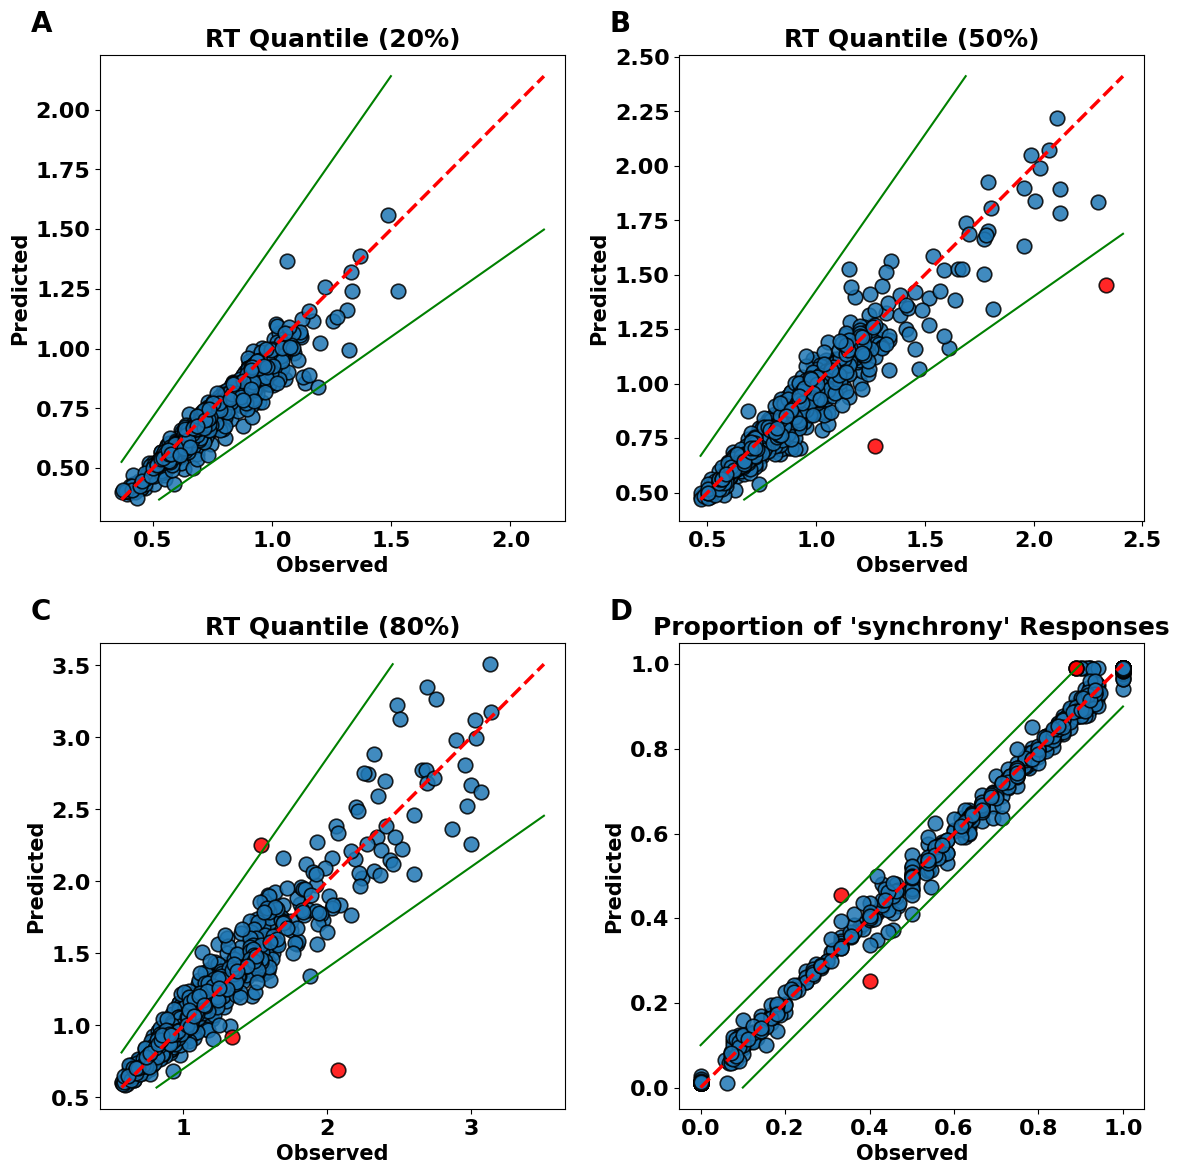

In [36]:
# Configure publication-ready figure formatting parameters
plt.rcParams.update({
    "font.size": 16,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold"
})

fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Define diagnostic dimensions (Panel D title updated to reflect accurate psychophysical measure)
plots = [
    (data_['q1'], model_['q1'], "RT Quantile (20%)"),
    (data_['q2'], model_['q2'], "RT Quantile (50%)"),
    (data_['q3'], model_['q3'], "RT Quantile (80%)"),
    (data_['p_vis'], model_['p_vis'], "Proportion of 'synchrony' Responses")
]

panel_labels = ["A", "B", "C", "D"]
R = [r1,r2,r3,r4]
# Iterate over grid cells and plot empirical vs. predicted measures
for i, ax, (x, y, title), label in zip(np.arange(4), axes.flatten(), plots, panel_labels):

    # Render individual participant-SOA data points
    ax.scatter(x[r], y[r],
               s=110,
               edgecolor="black",
               linewidth=1.2,
               alpha=0.85)
    ax.scatter(x[~R[i]], y[~R[i]],
               s=110,
               edgecolor="black",
               c='red',
               linewidth=1.2,
               alpha=0.85)

    # Plot the diagonal line of identity (y = x) representing perfect generative fit
    min_val = min(min(x.dropna()), min(y.dropna()))
    max_val = max(max(x.dropna()), max(y.dropna()))
    ax.plot([min_val, max_val], [min_val, max_val],
            color="red",
            linestyle='--',
            linewidth=2.5)
    if title=="Proportion of 'synchrony' Responses":
        ax.plot([.1, 1], [0, .9],
                color="green",
                linewidth=1.5)
        ax.plot([0, .9], [.1, 1],
                color="green",
                linewidth=1.5)
    else:
        ax.plot([1/.7*min_val, max_val], [min_val, .7*max_val],
                color="green",
                linewidth=1.5)
        ax.plot([min_val, .7*max_val], [1/.7*min_val, max_val],
                color="green",
                linewidth=1.5)

    ax.set_title(title, fontsize=18, fontweight="bold")
    ax.set_xlabel("Observed", fontsize=15)
    ax.set_ylabel("Predicted", fontsize=15)

    # Add panel identification labels (A-D)
    ax.text(-0.15, 1.05, label,
            transform=ax.transAxes,
            fontsize=20,
            fontweight="bold")

plt.tight_layout()

# Save vector PDF for manuscript integration and OSF repository
plt.savefig("figures/SJ_prior_stimulus_DDMfits.pdf",
            format="pdf",
            bbox_inches="tight")

plt.show()
plt.close()

###############################################################
## 2-3 Cross-Validation

Objective: \
This script executes an out-of-sample predictive cross-validation analysis to evaluate model ability to detect individual differences and generalizability and rule out potential overfitting in the TOJ paradigm. For each unique cell (Participant × Prior Response × SOA), trials are split into independent training (odd-indexed) and testing (even-indexed) subsets. The boundaries represent orthogonal temporal alternatives: Upper (1) for 'visual-first' (v) and Lower (0) for 'auditory-first' (a).Parameters are optimized via MLE on the training subset, and the predictive RT and choice statistics are validated against the held-out empirical testing set.

In [83]:
# split-half the data
current_df = df
current_df['trial_index'] = current_df.groupby(['participant', 'pre_stim', 'SOA']).cumcount()
df_odd = current_df[current_df['trial_index'] % 2 != 0].copy()   # Training Set (Odd trials)
df_even = current_df[current_df['trial_index'] % 2 == 0].copy()  # Testing Set (Even trials)

In [84]:
# fit the model on odd trials and calculate predictive and observed statistics
data_list = []
model_list = []

participants = current_df['participant'].unique()
pre_stims = current_df['pre_stim'].unique()
SOAs = current_df['SOA'].unique()

# Nested loops to isolate each model fitting cell independently
for participant in participants:
    print(participant)
    d_odd_p = df_odd[df_odd['participant'] == participant]
    d_even_p = df_even[df_even['participant'] == participant]
    
    for pre_stim in pre_stims:
        d_odd_pr = d_odd_p[d_odd_p['pre_stim'] == pre_stim]
        d_even_pr = d_even_p[d_even_p['pre_stim'] == pre_stim]
        
        for soa in SOAs:
            d_soa_train = d_odd_pr[d_odd_pr['SOA'] == soa].copy()
            d_soa_test = d_even_pr[d_even_pr['SOA'] == soa].copy()

            model = pyddm.gddm(drift="d", noise="noise", bound=1.0, nondecision='t0', starting_position="x0",
                               parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},
                               T_dur=d_soa_train['rt'].max() + 0.01)
            
            train_sample = Sample.from_pandas_dataframe(d_soa_train, rt_column_name="rt", choice_column_name="resp_num")
            model.fit(sample=train_sample, verbose=False, lossfunction=LossRobustLikelihood)
            
            
            p_obs = {
                'participant': participant,
                'SOA': soa,
                'pre_stim': pre_stim,
                'q1': d_soa_test['rt'].quantile(.2),
                'q2': d_soa_test['rt'].quantile(.5),
                'q3': d_soa_test['rt'].quantile(.8),
                'p_vis': d_soa_test['resp_num'].mean()
            }
            data_list.append(p_obs)
            s = model.solve()
            p_pred = {
                'participant': participant,
                'SOA': soa,
                'pre_stim': pre_stim,
                'q1': s.t_domain[s.cdf('correct') + s.cdf('error') <= .2][-1],
                'q2': s.t_domain[s.cdf('correct') + s.cdf('error') <= .5][-1],
                'q3': s.t_domain[s.cdf('correct') + s.cdf('error') <= .8][-1],
                'p_vis': s.prob('correct')
            }
            model_list.append(p_pred)
data_ = pd.DataFrame(data_list)
model_ = pd.DataFrame(model_list)

1


Info: Params [-3.12192732  0.47461363  0.74142006  0.51883113] gave -4.586682685770299
Info: Params [-1.52200437  0.80175577 -0.61377947  0.92627227] gave -2.759746337653941
Info: Params [-2.51007155  1.09450895  0.79042004  0.66402753] gave 2.1180070919922835
Info: Params [-0.03738202  1.4998187   0.73925603  0.51468018] gave -0.44610191966574897
Info: Params [5.         1.81306366 0.79946765 0.866151  ] gave -5.063857868539736
Info: Params [0.77598136 0.27392822 0.3789062  0.00304906] gave 1.2628135132899105
Info: Params [2.05930884 1.06242724 0.68449363 0.56989012] gave -4.353885625617196
Info: Params [1.55084345 0.69192712 0.16958461 0.20915094] gave 0.4703228717644409
Info: Params [2.36573949 0.7068755  0.10006092 0.41091227] gave -2.454373436668882
Info: Params [1.75495218 0.54353713 0.10426029 0.26134854] gave -1.1759273269035098
Info: Params [ 1.61194474  0.44910399 -0.08434468  0.00826116] gave -0.9741760098231163
Info: Params [ 1.73917776  0.49558226 -0.28431026  0.00437417] 

3


Info: Params [-1.30895521e+00  2.93282307e-01  5.35596250e-01  7.23322042e-04] gave -0.05839647998274711
Info: Params [-0.63835727  0.66487809 -0.69721238  1.0225867 ] gave 0.9869148989465374
Info: Params [-1.97939829  1.21523479  0.79611424  1.09950669] gave 0.9272083268933344
Info: Params [-1.03541305  1.31410817  0.13530173  0.98753172] gave 5.921745748188558
Info: Params [-0.63515187  0.79329678  0.52804318  1.15781611] gave 10.911288539874988
Info: Params [0.80019286 0.79347254 0.77286227 0.98732655] gave -1.2700898371996323
Info: Params [-0.25227322  0.84003749  0.35136205  0.72110043] gave 11.732622766455641
Info: Params [-1.22357897  0.49163277  0.79906505  0.95673061] gave 2.010097536131979
Info: Params [-0.0576326   0.80234881  0.72201756  0.75828491] gave 4.744076521427916
Info: Params [-0.42117456  0.78001913  0.7631162   1.3472009 ] gave 7.957710556413169
Info: Params [ 0.71130568  1.45334146 -0.14772627  1.25910598] gave 10.019341655901403
Info: Params [0.16701907 0.72831

4


Info: Params [-1.3138741   0.30170341  0.5062822   0.00298865] gave -0.008441924447925353
Info: Params [ 0.22219102  1.27124895 -0.45442894  0.71253422] gave 5.127933026145218
Info: Params [ 1.70824848  1.08854405 -0.66390313  0.67215789] gave 4.526395518961035
Info: Params [ 4.10696319  1.54472432 -0.79730342  0.83318127] gave -0.5223764292905213
Info: Params [0.05540482 1.43147007 0.56514885 0.74889074] gave 2.879908203955101
Info: Params [1.23116025 1.88205795 0.15265427 1.28523818] gave 1.0376298137626345
Info: Params [-0.74070174  1.3185504   0.10136699  0.6415042 ] gave 5.952836032188081
Info: Params [-0.04655087  1.04160588  0.54164278  0.86717403] gave 5.664622496132944
Info: Params [-0.11443632  1.09350656  0.66815864  0.88452437] gave 3.159791775323084
Info: Params [ 2.06429674  1.0519267  -0.62109476  0.62681584] gave 3.57220149264579
Info: Params [ 0.29583045  1.34177673 -0.17868807  0.74102045] gave 8.110341459822955
Info: Params [-2.38906563  1.18728126  0.79700182  0.727

... (26 outputs left out)

21


Info: Params [-0.38548552  0.5252855  -0.79021604  0.89585492] gave 1.7999308926719464
Info: Params [-1.08761603  0.82985221 -0.50467226  0.67008995] gave 1.3443363167535916
Info: Params [-5.          2.69512874  0.69805781  0.86837027] gave 1.792795104441558
Info: Params [1.88388078 1.74176027 0.17459877 0.87782561] gave 0.1882646381220976
Info: Params [2.00528975 1.62067924 0.7903823  0.90464019] gave -6.386037956650609
Info: Params [0.7409696  0.31017516 0.27026439 0.19939822] gave 3.0593746125148877
Info: Params [0.50330226 0.75737271 0.79602656 0.75017541] gave -0.04017115465060911
Info: Params [1.18052524 1.4321095  0.79866102 0.81726571] gave -4.021532478503069
Info: Params [2.29446039 1.20488826 0.63462675 0.71858978] gave -4.724578833611463
Info: Params [1.55876909 0.93346635 0.54839338 0.62951352] gave -1.768469282969618
Info: Params [1.14891527 0.12026621 0.19021443 0.06075023] gave -7.0443317225819735
Info: Params [2.67849478 0.87206414 0.09396197 0.54590287] gave -2.539855

22


Info: Params [-3.33626367  2.65407318  0.71370054  1.01697614] gave -2.5213457963670485
Info: Params [0.62131431 1.95199177 0.56745612 0.62207688] gave 0.18254408813163148
Info: Params [1.22135758 1.89104578 0.58926044 0.67553211] gave -5.145662148828579
Info: Params [4.12172639 1.24673807 0.23442851 0.51335628] gave -3.52544204716037
Info: Params [ 4.10605209  0.8615983  -0.0941316   0.41511295] gave -4.486815666009574
Info: Params [0.55609557 1.5975725  0.60947411 0.50637661] gave -1.4681028166087093
Info: Params [1.85386754 0.8946325  0.71988831 0.55408997] gave -6.072443158530977
Info: Params [ 2.75340784  0.23560675 -0.65885934  0.03652836] gave -8.98222972967519
Info: Params [ 1.87840546  0.32063662 -0.53139344  0.01180327] gave -1.8381863403962206
Info: Params [1.07483686 0.99389697 0.79512435 0.52585991] gave -3.44909056519307
Info: Params [0.84182339 1.49437951 0.79590427 0.56516022] gave -2.019027915006152
Info: Params [1.63771986 0.55868688 0.19184626 0.23036697] gave -0.726

In [87]:
model_.to_excel("files/SJ_prior_stimulus_DDM_crossval_model_.xlsx", index=False)

In [88]:
data_.to_excel("files/SJ_prior_stimulus_DDM_crossval_data_.xlsx", index=False)

In [91]:
model_ = model_.sort_values(['participant', 'SOA', 'pre_stim']).reset_index(drop=True)

In [92]:
data_ = data_.sort_values(['participant', 'SOA', 'pre_stim']).reset_index(drop=True)

In [94]:
# delete excluded fits
model_ = model_[r].reset_index(drop=True)

In [95]:
data_ = data_[r].reset_index(drop=True)

In [102]:
spearmanr(data_['q1'],model_['q1'])

SignificanceResult(statistic=np.float64(0.7655950494629927), pvalue=np.float64(1.7362193528072942e-158))

In [105]:
spearmanr(data_['q2'],model_['q2'])

SignificanceResult(statistic=np.float64(0.7477129167870454), pvalue=np.float64(2.9701262198647834e-147))

In [108]:
spearmanr(data_['q3'],model_['q3'])

SignificanceResult(statistic=np.float64(0.700573157695478), pvalue=np.float64(1.0220397648153423e-121))

In [111]:
spearmanr(data_['p_vis'],model_['p_vis'])

SignificanceResult(statistic=np.float64(0.7794222013649799), pvalue=np.float64(6.932572528362503e-168))

###############################################################\
###############################################################
# 3- DDM for general data

In [15]:
df = pd.read_excel("files/SJ_general_data.xlsx")

In [16]:
df['resp_num'] = df['resp'].map({'synchrony': 1, 'asynchrony': 0})

In [17]:
df

,participant,SOA,resp,rt,resp_num
0,1,-400,asynchrony,1.437342,0
1,1,-400,asynchrony,1.169998,0
2,1,-400,asynchrony,1.236840,0
3,1,-400,asynchrony,1.186734,0
4,1,-400,asynchrony,1.403907,0
...,...,...,...,...,...
12006,22,400,asynchrony,0.785775,0
12007,22,400,asynchrony,0.852618,0
12008,22,400,asynchrony,0.786604,0
12009,22,400,asynchrony,0.719479,0


In [4]:
# DataFrame to store the final results
params = pd.DataFrame()

# List of participants
participants = df['participant'].unique()

# List of SOAs available in the participant's data (regardless of pre_resp)
SOAs = df['SOA'].unique()

# Loop over each participant
for participant in participants:
    print(participant)
    # Filter data for the specific participant
    d = df[df['participant'] == participant]

    # Loop over each SOA
    for soa in SOAs:
        # Filter data for the specific SOA
        d_soa = d[d['SOA'] == soa]



        # Fit the DDM model with variable noise and fixed boundary = 1
        model = pyddm.gddm(drift="d",
                           noise="noise",  # noise as a free parameter
                           bound=1.0,      # fix boundary at 1
                           nondecision='t0', 
                           starting_position="x0",
                           parameters={"d": (-5, 5), "noise": (0.1, 3), "x0": (-.8, .8), 't0': (0, 2)},  # parameters to be fitted
                           T_dur=d_soa['rt'].max() + 0.01)

        # Prepare data for the model
        data = Sample.from_pandas_dataframe(d_soa, rt_column_name="rt", choice_column_name="resp_num")

        # Fit the model to the data
        model.fit(sample=data, lossfunction=LossRobustLikelihood, verbose=False)

        # Extract fitted parameters
        p = model.parameters()

        # Create a DataFrame to store results for this SOA and participant (pre_resp removed)
        pp = pd.DataFrame({
            'participant': [participant],
            'SOA': [soa],
            'drift': [p['drift']['drift']],
            'noise': [p['noise']['noise']],  # store noise as a fitted parameter
            'bound': [1.0],                  # fixed boundary value
            'Z': [p['IC']['x0']],
            't0': [p['overlay']['nondectime']]
        })

        # Append results to the final DataFrame
        params = pd.concat([params, pp], ignore_index=True)

1


Info: Params [-2.38983256  0.63883458  0.14581855  0.65266663] gave -9.87337733685412
Info: Params [-2.70446172  0.88069536  0.52809516  0.59348444] gave -0.582979132391279
Info: Params [-1.08484118  1.19225151  0.5541853   0.62744428] gave 21.86375790244962
Info: Params [1.09969988 1.23299493 0.25097471 0.46974717] gave 14.572219389680239
Info: Params [1.26015412 0.57538299 0.30042614 0.36410931] gave 3.596894646066817
Info: Params [ 1.73320433e+00  5.20495521e-01 -4.17316464e-01  8.52693239e-04] gave 11.847906050046475
Info: Params [1.38554689 0.47800203 0.28655423 0.29800761] gave -3.306581246970305
Info: Params [ 1.58378346e+00  4.30476263e-01 -2.19777330e-01  1.30471743e-03] gave 3.082968676729529
Info: Params [1.23660664 0.42696364 0.10952419 0.06783796] gave 2.921378345907062
Info: Params [8.53526991e-01 2.52549544e-01 3.00136035e-01 3.57444968e-04] gave 6.797030995928226
Info: Params [ 1.59092984  0.50882146 -0.1043392   0.09268876] gave 0.348714369490586
Info: Params [1.140062

3


Info: Params [-1.78080147  0.41957203  0.44390563  0.36358212] gave 0.8545790307076243
Info: Params [-0.93063528  0.99865175 -0.24445449  0.79309368] gave 28.781342286181165
Info: Params [-0.65951467  0.93493707  0.32548757  0.87907808] gave 42.480457916219066
Info: Params [-0.44519918  0.85994891  0.45835118  0.72255071] gave 44.56832434647257
Info: Params [-0.17538552  0.71608093  0.46842132  0.62280199] gave 56.72688709884383
Info: Params [0.10864249 0.79275569 0.40508278 0.60992373] gave 43.644611085682975
Info: Params [-0.142586    0.77848217  0.46067295  0.73302301] gave 54.32890941342846
Info: Params [-0.246806    0.70987424  0.53083545  0.61424257] gave 50.98280659527151
Info: Params [-0.26990455  0.63952877  0.58422889  0.55900564] gave 51.42933535503205
Info: Params [-0.04422204  0.8042381   0.40234774  0.79213116] gave 51.89429621158699
Info: Params [-0.27955131  0.71606108  0.5018843   0.48145239] gave 52.18210448690208
Info: Params [-0.02888826  0.7738624   0.42931124  0.5

4


Info: Params [-1.4339835   0.27062924  0.68651292  0.003212  ] gave 5.556203265518937
Info: Params [ 0.26822521  1.1898023  -0.41446     0.69265672] gave 30.338119567590297
Info: Params [ 0.45447094  1.01311084 -0.27962102  0.63074658] gave 43.77958127645128
Info: Params [ 1.35013673  1.29263416 -0.39003068  0.67148372] gave 23.24308309784798
Info: Params [ 0.68386915  0.99604637 -0.27430576  0.49672135] gave 42.122010373428644
Info: Params [ 0.98591829  1.36260544 -0.05074319  0.70686332] gave 26.644396077923922
Info: Params [ 0.71037268  1.36763818 -0.05707451  0.69869468] gave 27.40190873712134
Info: Params [ 0.49663866  1.05805919 -0.10356442  0.56594127] gave 38.929077199435156
Info: Params [0.1259089  1.52647653 0.19597628 0.72250126] gave 19.206409180422813
Info: Params [ 1.20943875  1.16900156 -0.47866004  0.61687301] gave 26.62390733463787
Info: Params [ 0.77314999  1.11657114 -0.18073451  0.64709126] gave 35.71039955812493
Info: Params [0.19646549 1.23392635 0.09612476 0.5074

... (26 outputs left out)

21


Info: Params [-1.99429834  0.72822832 -0.37891212  0.77115845] gave -6.268870523779871
Info: Params [-1.40389981  1.16383033  0.2226731   0.56838703] gave 24.30321124757816
Info: Params [ 0.83352643  1.12842811 -0.32426356  0.65216464] gave 31.620898299431882
Info: Params [0.91416716 1.12873467 0.09857435 0.67925578] gave 25.272527162898587
Info: Params [1.4201163  0.58613999 0.12475613 0.4217464 ] gave 3.9591507051495545
Info: Params [0.94030247 0.54099032 0.35933953 0.51036428] gave 12.068992333593558
Info: Params [0.78969351 0.40317263 0.50542838 0.45026704] gave 7.821930129186736
Info: Params [0.97502789 0.5359682  0.53824089 0.61163488] gave 3.2989000589257285
Info: Params [ 2.28508693  0.43533029 -0.42802989  0.30317514] gave -13.937490575014191
Info: Params [1.46624431 0.57256294 0.15129427 0.41996236] gave 1.5270783562571193
Info: Params [1.25503019 0.56848455 0.22708811 0.38601593] gave 5.613775204790342
Info: Params [ 1.91114816  0.39345239 -0.50776157  0.08725564] gave -8.40

22


Info: Params [-0.33899915  1.3328211  -0.13562602  0.53472588] gave 24.685880108449226
Info: Params [0.3446788  1.36955997 0.22126347 0.53230933] gave 22.19632168287645
Info: Params [2.41277667 2.05834068 0.28227652 0.64951577] gave -10.180279816767671
Info: Params [ 4.30959706  1.16442369 -0.48696001  0.43866769] gave -13.972142781164198
Info: Params [2.48731602 1.42749657 0.3626261  0.52907678] gave -10.848191353164198
Info: Params [1.93315049 1.43942009 0.2208878  0.46689841] gave 1.1813881426756296
Info: Params [ 2.73398803  1.23883509 -0.00480119  0.39022407] gave -1.2780921395341753
Info: Params [ 4.81865217  1.50050193 -0.15159069  0.44157722] gave -18.544614168688483
Info: Params [3.30430104 1.31363726 0.06268148 0.46087591] gave -10.955655004872371
Info: Params [1.80321576 0.94318546 0.31282902 0.4244322 ] gave 1.604680250750592
Info: Params [1.27055962 1.42243106 0.51072439 0.5001947 ] gave 2.711540098348342
Info: Params [2.67846275 1.77207331 0.16721912 0.50205845] gave -1.0

In [5]:
# save parameters:
params.to_excel("files/SJ_general_DDM_parameters.xlsx", index=False)